# Fresh-data continuation and cosine annealing

All seven runs fork from the same step-100,000 checkpoint at validation loss
3.7271. They retain Adam state, use the same fresh-data prefix, and evaluate on
the same held-out windows. The constant-LR control runs for 20,000 additional
updates. Each anneal starts at base LR 0.00078125 and reaches zero at its endpoint.

Each update processes 20,480 training targets. Compare endpoints with the
control at the same step to hold data exposure fixed. Run the cells to refresh
the saved plots using only the analysis environment.

In [1]:
import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").is_file())
runs = root / "artifacts" / "pretraining"
prefix = "gpt-mlx-mup-width256-fresh-constant-control-01"
budgets = [1000, 3000, 6000, 10000, 15000, 20000]
export = root / "artifacts" / "analysis" / "fresh-anneal"
export.mkdir(parents=True, exist_ok=True)

def load(name):
    path = runs / name
    metadata = json.loads((path / "metadata.json").read_text())
    with (path / "metrics.csv").open() as file:
        rows = [dict(step=int(r["step"]), loss=float(r["val_loss"]),
                     lr=float(r["learning_rate"]) if r.get("learning_rate") else None)
                for r in csv.DictReader(file) if r["val_loss"]]
    return rows, metadata

control, control_meta = load(prefix)
branches = {}
fork = control[0]["step"]
control_losses = {r["step"]: r["loss"] for r in control}
for budget in budgets:
    rows, metadata = load(f"{prefix}-anneal-{budget}-01")
    assert metadata["resume_anneal"]["checkpoint_step"] == fork
    assert metadata["resume_anneal"]["steps"] == budget
    assert metadata["token_cache"] == control_meta["token_cache"]
    assert metadata["model_config"] == control_meta["model_config"]
    assert metadata["data_start_step"] == control_meta["data_start_step"] == fork
    assert metadata["resumed_from"] == control_meta["resumed_from"]
    assert rows[0]["loss"] == control[0]["loss"]
    assert rows[-1]["step"] == fork + budget and rows[-1]["lr"] == 0
    assert rows[-1]["step"] in control_losses
    branches[budget] = rows
assert control[-1]["step"] == fork + 20000
colors = dict(zip(budgets, plt.get_cmap("tab10").colors))

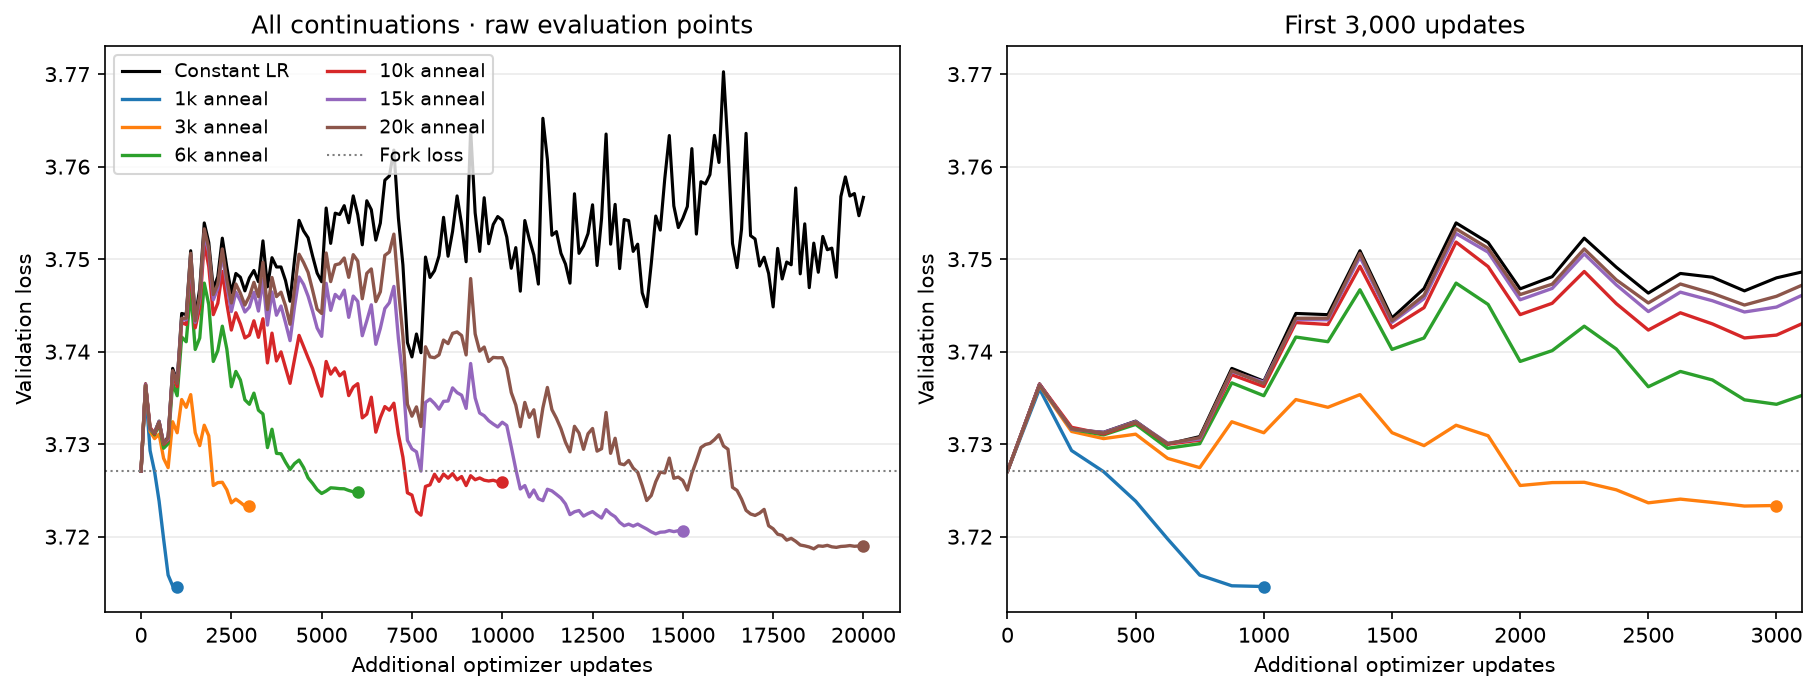

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for ax in axes:
    ax.plot([r["step"] - fork for r in control], [r["loss"] for r in control],
            color="black", lw=1.5, label="Constant LR")
    for budget, rows in branches.items():
        ax.plot([r["step"] - fork for r in rows], [r["loss"] for r in rows],
                color=colors[budget], lw=1.6, label=f"{budget // 1000}k anneal")
        ax.scatter(budget, rows[-1]["loss"], color=colors[budget], s=25, zorder=4)
    ax.axhline(control[0]["loss"], ls=":", color="gray", lw=1, label="Fork loss")
    ax.set(xlabel="Additional optimizer updates", ylabel="Validation loss")
    ax.grid(axis="y", alpha=.25)
axes[0].set_title("All continuations · raw evaluation points")
axes[1].set(title="First 3,000 updates", xlim=(0, 3100))
axes[0].legend(ncol=2, fontsize=9)
fig.savefig(export / "trajectories.png", dpi=170)
plt.show()

Budget    Anneal     Control    Difference
  1000    3.71462    3.73681    -0.02219
  3000    3.72337    3.74798    -0.02461
  6000    3.72479    3.75480    -0.03002
 10000    3.72594    3.75422    -0.02828
 15000    3.72063    3.75441    -0.03378
 20000    3.71895    3.75668    -0.03773


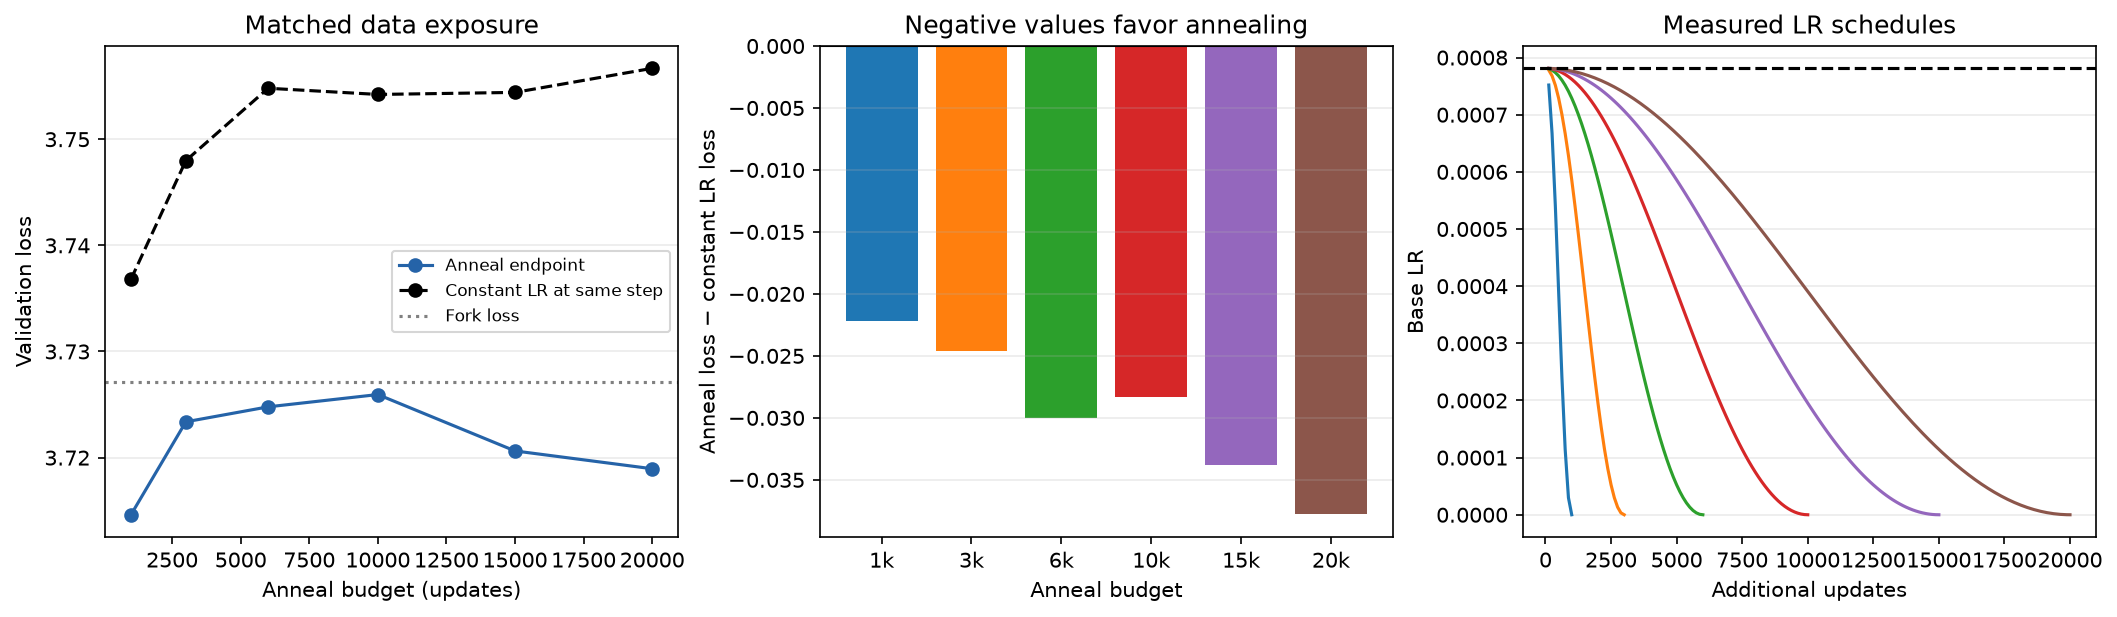

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
ends = [branches[n][-1]["loss"] for n in budgets]
matched = [control_losses[fork + n] for n in budgets]
axes[0].plot(budgets, ends, "o-", color="#2563a8", label="Anneal endpoint")
axes[0].plot(budgets, matched, "o--", color="black", label="Constant LR at same step")
axes[0].axhline(control[0]["loss"], ls=":", color="gray", label="Fork loss")
axes[0].set(xlabel="Anneal budget (updates)", ylabel="Validation loss", title="Matched data exposure")
axes[0].legend(fontsize=8)
axes[1].bar([f"{n//1000}k" for n in budgets],
            [a-b for a,b in zip(ends,matched)], color=[colors[n] for n in budgets])
axes[1].axhline(0, color="black", lw=1)
axes[1].set(xlabel="Anneal budget", ylabel="Anneal loss − constant LR loss",
            title="Negative values favor annealing")
for budget, rows in branches.items():
    axes[2].plot([r["step"]-fork for r in rows if r["lr"] is not None],
                 [r["lr"] for r in rows if r["lr"] is not None],
                 color=colors[budget], label=f"{budget//1000}k")
axes[2].axhline(control[1]["lr"], color="black", ls="--")
axes[2].set(xlabel="Additional updates", ylabel="Base LR", title="Measured LR schedules")
for ax in axes:
    ax.grid(axis="y", alpha=.25)
fig.savefig(export / "endpoints-and-schedules.png", dpi=170)
plt.show()
print("Budget    Anneal     Control    Difference")
for n, a, b in zip(budgets, ends, matched):
    print(f"{n:6d}    {a:.5f}    {b:.5f}    {a-b:+.5f}")

The best anneal endpoint is the 1k branch at **3.7146**, compared with the fork’s
3.7271. Extending the anneal to 20k reaches **3.7190**. The constant-LR control
finishes at **3.7567**. Every tested anneal beats the control at its own endpoint,
but longer budgets give little additional benefit to endpoint validation loss
in this experiment. The base run’s best recorded loss was 3.7107 at step 92,500.

These are single trajectories with a fixed validation probe. The plots show
raw measurements and the comparisons use matching data exposure. The previous
4k anneal reused the original corpus, so its 3.6997 endpoint belongs to a
different data comparison.

## Larger effective batches at the 1k token budget

All four trials start at the same step-100,000 weights and optimizer state.
They use the same 20.48M fresh-target prefix, starting LR and cosine cooldown.
Increasing accumulation by 2×, 4× and 8× reduces optimizer updates to 500,
250 and 125. Each endpoint has zero LR. The plots align training by added
tokens because optimizer step counts differ.

Gradient-noise probes average four independent batches at the same weights.
Each trial uses its own effective batch size for these probes. Their raw
gradients are measured before clipping and Adam preconditioning.

Batch  Updates  Final loss  Variance  Signal²   Noise/signal  Cosine
  1×    1000    3.714617 0.04654 0.000618        75.37 0.013
  2×     500    3.710830 0.02294 0.001290        17.78 0.053
  4×     250    3.709646 0.01095 0.001651         6.63 0.131
  8×     125    3.710853 0.00574 0.001832         3.13 0.241


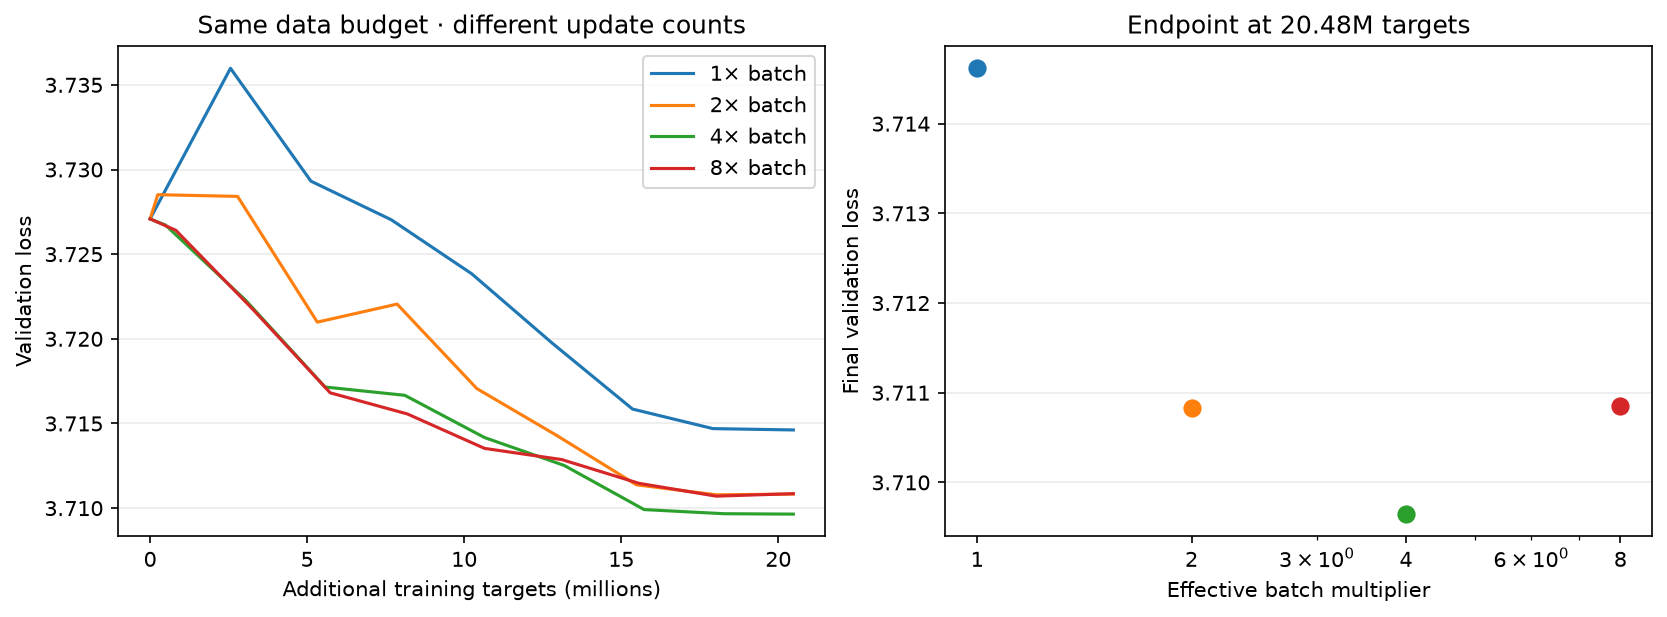

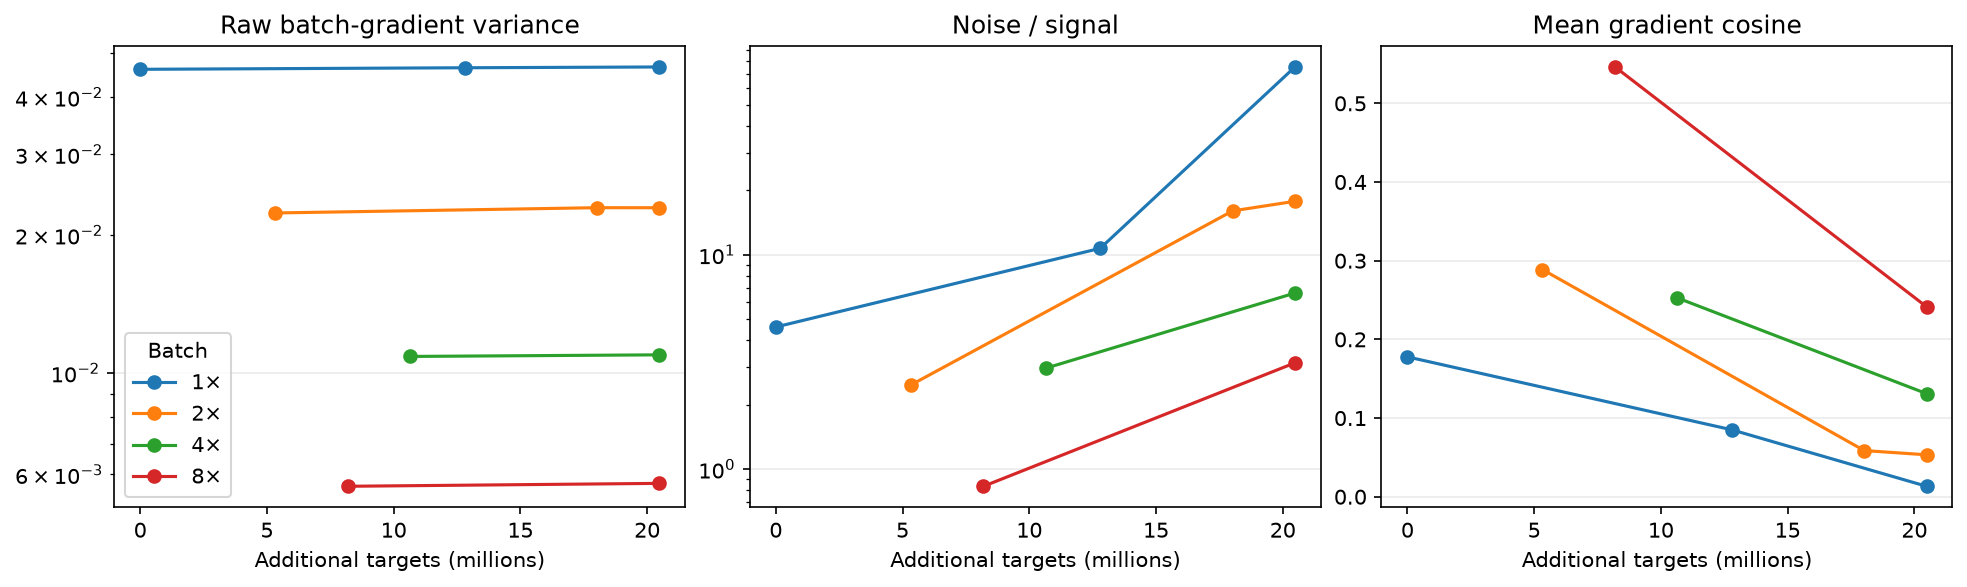

In [4]:
import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
runs = root / "artifacts" / "pretraining"
export = root / "artifacts" / "analysis" / "fresh-anneal"
export.mkdir(parents=True, exist_ok=True)
factors = [1, 2, 4, 8]
trial_names = {
    1: "gpt-mlx-mup-width256-fresh-constant-control-01-anneal-1000-01",
    **{f: f"gpt-mlx-mup-width256-fresh-batch{f}x-01-anneal-{1000//f}-01"
       for f in factors[1:]},
}
trials = {}
for factor, name in trial_names.items():
    directory = runs / name
    meta = json.loads((directory / "metadata.json").read_text())
    with (directory / "metrics.csv").open() as file:
        metrics = [r for r in csv.DictReader(file) if r["val_loss"]]
    stats = [json.loads(line) for line in (directory / "statistics.jsonl").read_text().splitlines()]
    assert meta["resume_anneal"]["checkpoint_step"] == 100000
    assert meta["tokens_per_update"] == 20480 * factor
    assert int(metrics[-1]["step"]) == 100000 + 1000 // factor
    assert float(metrics[-1]["learning_rate"]) == 0
    if trials:
        baseline = trials[1]["meta"]
        for key in ("model_config", "token_cache", "resumed_from", "data_start_step"):
            assert meta[key] == baseline[key]
    trials[factor] = dict(meta=meta, metrics=metrics,
                          noise=[r for r in stats if r.get("gradient_noise")])
colors = plt.get_cmap("tab10").colors
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for index, factor in enumerate(factors):
    trial = trials[factor]
    tokens_per_step = trial["meta"]["tokens_per_update"]
    axes[0].plot([(int(r["step"])-100000)*tokens_per_step/1e6 for r in trial["metrics"]],
                  [float(r["val_loss"]) for r in trial["metrics"]],
                  label=f"{factor}× batch", color=colors[index])
    axes[1].scatter(factor, float(trial["metrics"][-1]["val_loss"]),
                    color=colors[index], s=60)
axes[0].set(xlabel="Additional training targets (millions)", ylabel="Validation loss",
            title="Same data budget · different update counts")
axes[0].legend()
axes[1].set(xscale="log", xlabel="Effective batch multiplier", ylabel="Final validation loss",
            title="Endpoint at 20.48M targets", xticks=factors, xticklabels=factors)
for ax in axes: ax.grid(axis="y", alpha=.25)
fig.savefig(export / "batch-losses.png", dpi=170)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for index, factor in enumerate(factors):
    trial = trials[factor]
    rows = trial["noise"]
    tokens = [(r["step"]-100000)*trial["meta"]["tokens_per_update"]/1e6 for r in rows]
    for ax, key in zip(axes, ("batch_gradient_variance", "noise_to_signal", "mean_pairwise_cosine")):
        ax.plot(tokens, [r["gradient_noise"][key] for r in rows],
                marker="o", color=colors[index], label=f"{factor}×")
axes[0].set(title="Raw batch-gradient variance", yscale="log")
axes[1].set(title="Noise / signal", yscale="log")
axes[2].set(title="Mean gradient cosine")
for ax in axes:
    ax.set_xlabel("Additional targets (millions)")
    ax.grid(axis="y", alpha=.25)
axes[0].legend(title="Batch")
fig.savefig(export / "batch-noise.png", dpi=170)
plt.show()
print("Batch  Updates  Final loss  Variance  Signal²   Noise/signal  Cosine")
for factor, trial in trials.items():
    noise = trial["noise"][-1]["gradient_noise"]
    print(f'{factor:>3}× {1000//factor:>7} {float(trial["metrics"][-1]["val_loss"]):>11.6f}'
          f' {noise["batch_gradient_variance"]:.5f} {noise["signal_squared_estimate"]:.6f}'
          f' {noise["noise_to_signal"]:>12.2f} {noise["mean_pairwise_cosine"]:.3f}')

The 4× batch has the lowest endpoint loss, 3.70965, versus 3.71462 for the
baseline. The 2× and 8× results are both about 3.71085. The differences among
larger batches are small in this single fork experiment.

Endpoint raw gradient variance falls roughly inversely with batch size
(0.04654, 0.02294, 0.01095, 0.00574). Mean gradient cosine rises from 0.013
to 0.241. Final noise/signal ratios are 75.37, 17.78, 6.63 and 3.13.
Larger-batch endpoints have both lower variance and a larger estimated shared
signal. These endpoints are at different learned weights, so the probe curves
also include changes in the model during each cooldown.

These probes use four batches and reused fixed windows. Small signal estimates
make the ratio sensitive to sampling. Changing batch size also changes how many
Adam updates happen per token, while the existing moments and update count carry
over from pretraining. This experiment supports larger batches for this cooldown
budget, with a modest validation gain.

## Staircase anneals

Solid curves hold the LR between drops. Dashed curves show matched-budget cosine anneals. All use effective batch 80 and start from the same checkpoint on the same fresh prefix.


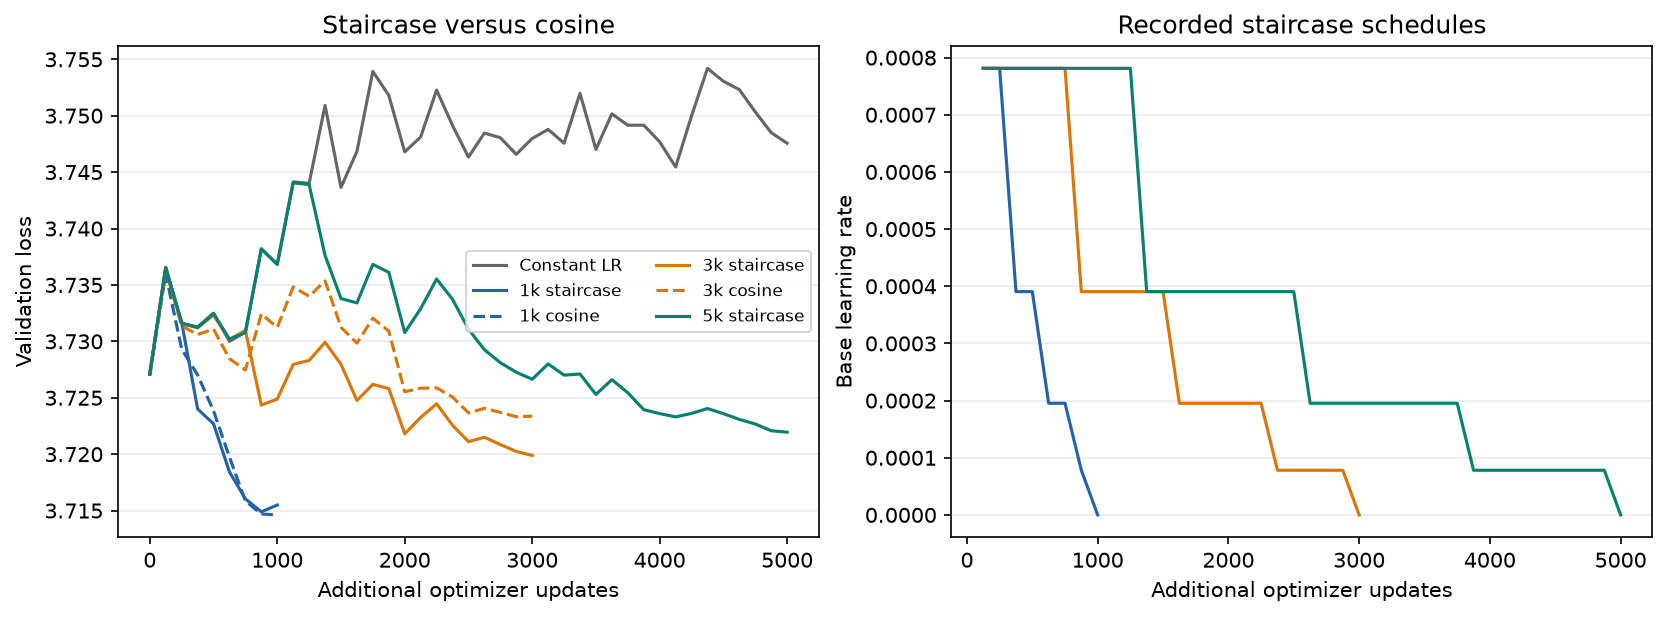

In [5]:
import csv
import json
from pathlib import Path
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
runs = root / "artifacts" / "pretraining"

def read_metrics(name):
    with (runs / name / "metrics.csv").open() as file:
        return [r for r in csv.DictReader(file) if r["val_loss"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
prefix = "gpt-mlx-mup-width256-fresh"
control = read_metrics(prefix + "-constant-control-01")
axes[0].plot([int(r["step"])-100000 for r in control if int(r["step"]) <= 105000],
             [float(r["val_loss"]) for r in control if int(r["step"]) <= 105000],
             color="black", alpha=.6, label="Constant LR")
for n, color in zip((1000, 3000, 5000), ("#2563a8", "#d97706", "#087f73")):
    name = f"{prefix}-staircase-{n}-01-anneal-{n}-01"
    rows = read_metrics(name)
    meta = json.loads((runs / name / "metadata.json").read_text())
    assert meta["resume_anneal"]["schedule"] == "staircase"
    assert rows[0]["val_loss"] == control[0]["val_loss"]
    assert int(rows[-1]["step"]) == 100000+n and float(rows[-1]["learning_rate"]) == 0
    axes[0].plot([int(r["step"])-100000 for r in rows],
                 [float(r["val_loss"]) for r in rows], color=color, label=f"{n//1000}k staircase")
    axes[1].plot([int(r["step"])-100000 for r in rows if r["learning_rate"]],
                 [float(r["learning_rate"]) for r in rows if r["learning_rate"]],
                 color=color, label=f"{n//1000}k staircase")
    if n in (1000, 3000):
        cosine = read_metrics(f"{prefix}-constant-control-01-anneal-{n}-01")
        axes[0].plot([int(r["step"])-100000 for r in cosine],
                     [float(r["val_loss"]) for r in cosine],
                     color=color, ls="--", label=f"{n//1000}k cosine")
axes[0].set(ylabel="Validation loss", title="Staircase versus cosine")
axes[1].set(ylabel="Base learning rate", title="Recorded staircase schedules")
for ax in axes:
    ax.set_xlabel("Additional optimizer updates")
    ax.grid(axis="y", alpha=.25)
axes[0].legend(fontsize=8, ncol=2)
fig.savefig(root / "artifacts/analysis/fresh-anneal/staircase.png", dpi=170)
plt.show()

The staircase endpoints are 3.71549 (1k), 3.71989 (3k), and 3.72195 (5k). Matched cosine endpoints are 3.71462 (1k) and 3.72337 (3k). The 1k difference is +0.00088, and the 3k difference is −0.00349 for staircase minus cosine. No 5k cosine run was collected. All three staircase endpoints beat constant LR at the same added steps. Final noise/signal estimates are 27.04, 36.55, and 36.43 from four-batch raw-gradient probes. These small single-run loss differences give limited evidence for a schedule preference.
